# 📈 Financial Analytics — Séries Temporais: Fundamentos e Modelagem SARIMA

**Autores:** Paloma Vaissman Uribe & Julio Trecenti  
**Instituição:** Insper — PADS | **Ano:** 2026

---

Este notebook acompanha os slides da **Aula 1** e cobre as 4 partes:

- **Parte 1 — Fundamentos:** processo estocástico, i.i.d., ACF, estacionariedade, random walk, ruído branco
- **Parte 2 — Componentes e Decomposição:** tabela de componentes, decomposição, diff sazonal, dummy Covid, ADF
- **Parte 3 — PACF e Modelos:** PACF, padrões teóricos AR/MA/ARMA, ACF/PACF do IBC-Br, ARIMA, SARIMA
- **Parte 4 — Modelagem na Prática:** guia Box-Jenkins, AutoARIMA, previsão com IC

> Série de referência: **IBC-Br (BCB 24363)** — proxy mensal do PIB brasileiro


### ⚙️ Instalação

In [1]:
import subprocess, sys
for pkg in ['statsmodels', 'statsforecast']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
print("✅ Pacotes instalados!")


✅ Pacotes instalados!


In [2]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor':'#FFFFFF','axes.facecolor':'#F9F9F9',
    'axes.edgecolor':'#BBBBBB','axes.labelcolor':'#1C1C1C',
    'xtick.color':'#444444','ytick.color':'#444444',
    'text.color':'#1C1C1C','grid.color': '#DDDDDD',
    'grid.linestyle':'--','grid.alpha':0.5,'figure.dpi':110,
})
RED,BLUE,GREEN,GRAY,YELLOW='#E4002B','#1a6fc4','#1a9b57','#555555','#cc8800'

def bcb_serie(codigo, start='2003-01-01'):
    """Carrega série do BCB via API REST — sem dependências extras."""
    di  = pd.Timestamp(start).strftime('%d/%m/%Y')
    url = (f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados"
           f"?formato=json&dataInicial={di}")
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    df = pd.DataFrame(resp.json())
    df['data']  = pd.to_datetime(df['data'], dayfirst=True)
    df['valor'] = pd.to_numeric(df['valor'], errors='coerce')
    return df.set_index('data').rename(columns={'valor': f'bcb_{codigo}'}).dropna()

print("✅ Imports e função bcb_serie() prontos!")


Matplotlib is building the font cache; this may take a moment.


✅ Imports e função bcb_serie() prontos!


---
## 🔴 Parte 1 — Fundamentos

### 1.1 · Variável Aleatória e Processo i.i.d.

Uma **variável aleatória** associa a cada resultado $\omega \in \Omega$ do espaço amostral um número real:
$$X: \Omega \to \mathbb{R}$$

Um **processo i.i.d.** ocorre quando as VAs são **independentes e identicamente distribuídas** — sem memória entre os pontos.


In [3]:
# Simular 500 lançamentos de um dado de 6 faces
np.random.seed(42)
n = 500

def dados(n, k):
    """Simula n lançamentos de um dado de k faces."""
    return np.random.randint(1, k + 1, size=n)

dados_gerados = dados(n, 6)
print(f"Primeiros 20 resultados: {dados_gerados[:20]}")
print(f"Média amostral: {dados_gerados.mean():.3f}  (esperado: 3.5)")


Primeiros 20 resultados: [4 5 3 5 5 2 3 3 3 5 4 3 6 5 2 4 6 6 2 4]
Média amostral: 3.500  (esperado: 3.5)


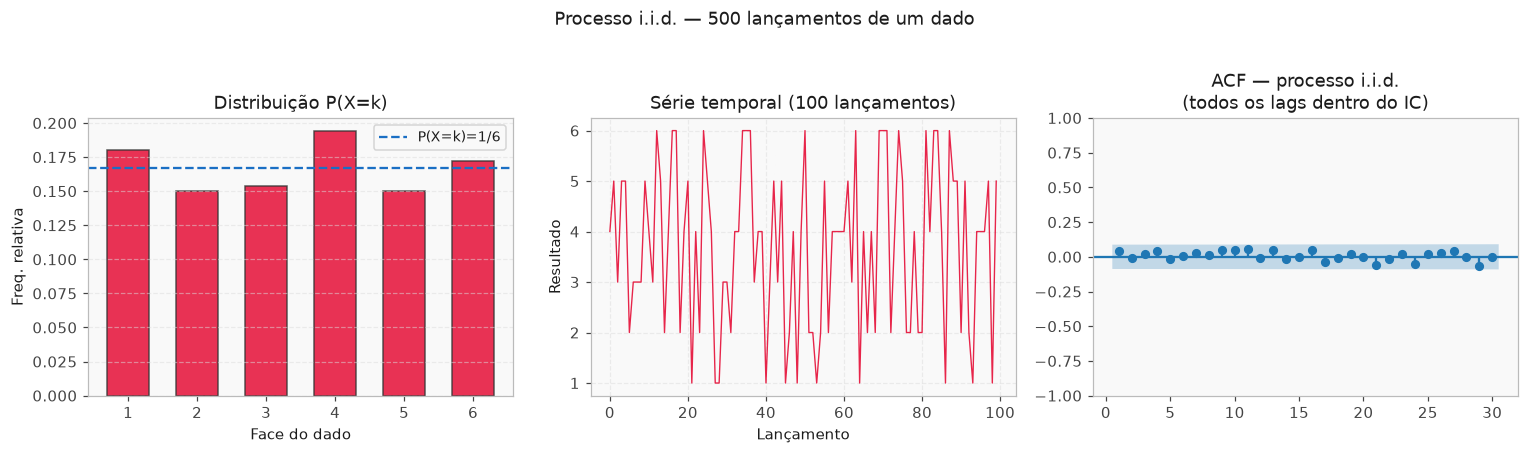

Lags fora do IC 95%: 0/30  (por acaso ~1-2 esperados)
✅ ACF limpa → processo i.i.d., sem memória!


In [4]:
# Visualização: distribuição + série temporal + ACF
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Distribuição empírica
counts = np.bincount(dados_gerados, minlength=7)[1:]
axes[0].bar(range(1,7), counts/n, color=RED, alpha=0.8, width=0.6, edgecolor='#333')
axes[0].axhline(1/6, color=BLUE, lw=1.5, ls='--', label='P(X=k)=1/6')
axes[0].set_title('Distribuição P(X=k)')
axes[0].set_xlabel('Face do dado'); axes[0].set_ylabel('Freq. relativa')
axes[0].set_xticks(range(1,7)); axes[0].legend(fontsize=9); axes[0].grid(True, axis='y')

# Série temporal
axes[1].plot(dados_gerados[:100], color=RED, lw=0.9, alpha=0.85)
axes[1].set_title('Série temporal (100 lançamentos)')
axes[1].set_xlabel('Lançamento'); axes[1].set_ylabel('Resultado')
axes[1].set_yticks(range(1,7)); axes[1].grid(True)

# ACF — deve estar toda dentro do IC
plot_acf(dados_gerados, ax=axes[2], lags=30, zero=False,
         title='ACF — processo i.i.d.\n(todos os lags dentro do IC)')

plt.suptitle('Processo i.i.d. — 500 lançamentos de um dado', fontsize=12, y=1.02)
plt.tight_layout(); plt.show()

# Verificar
from statsmodels.tsa.stattools import acf as acf_func
acf_vals = acf_func(dados_gerados, nlags=30)[1:]
ci = 1.96/np.sqrt(n)
fora = np.sum(np.abs(acf_vals) > ci)
print(f"Lags fora do IC 95%: {fora}/30  (por acaso ~1-2 esperados)")
print("✅ ACF limpa → processo i.i.d., sem memória!")


### 1.2 · Carregando o IBC-Br

In [5]:
# IBC-Br (BCB 24363) via API REST — sem python_bcb
ibc_raw = bcb_serie(24363, start='2003-01-01')
ibc_raw.columns = ['ibc']
try:
    ibc_raw = ibc_raw.asfreq('MS')
except: pass

ibc = ibc_raw.copy()
print(f"✅ IBC-Br carregado!")
print(f"   Período: {ibc.index[0].date()} → {ibc.index[-1].date()}")
print(f"   Observações: {len(ibc)}")
ibc.head()


✅ IBC-Br carregado!
   Período: 2003-01-01 → 2026-07-01
   Observações: 283


,ibc
data,
2003-01-01,67.21946
2003-02-01,68.97643
2003-03-01,72.29326
2003-04-01,71.43628
2003-05-01,70.11520


### 1.3 · ACF do IBC-Br em Nível

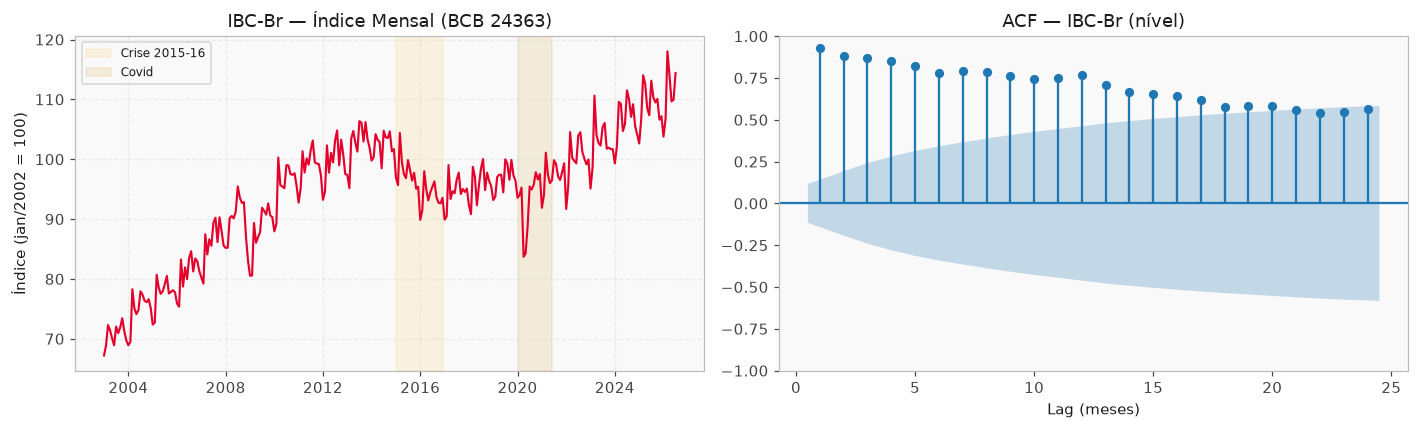

💡 ACF decai lentamente → não-estacionária → raiz unitária!


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(ibc.index, ibc['ibc'], color=RED, lw=1.4)
axes[0].set_title('IBC-Br — Índice Mensal (BCB 24363)')
axes[0].set_ylabel('Índice (jan/2002 = 100)'); axes[0].grid(True)
axes[0].axvspan(pd.Timestamp('2015-01-01'), pd.Timestamp('2016-12-01'),
                alpha=0.1, color='orange', label='Crise 2015-16')
axes[0].axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-06-01'),
                alpha=0.12, color=YELLOW, label='Covid')
axes[0].legend(fontsize=8)

plot_acf(ibc['ibc'], ax=axes[1], lags=24, zero=False, title='ACF — IBC-Br (nível)')
axes[1].set_xlabel('Lag (meses)')

plt.tight_layout(); plt.show()
print("💡 ACF decai lentamente → não-estacionária → raiz unitária!")


### 1.4 · Estacionariedade — Defasagem e Diferenciação

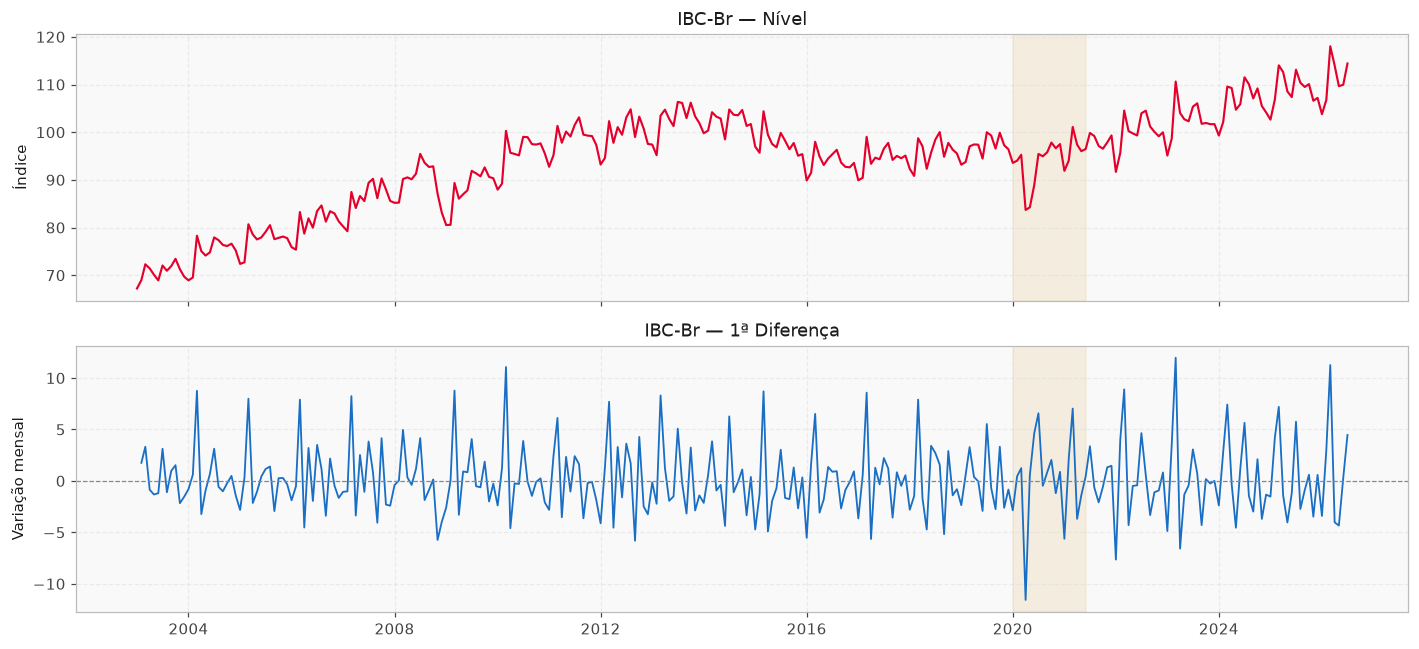

In [7]:
# Criar defasagem e 1ª diferença
ibc['ibc_lag1'] = ibc['ibc'].shift(1)
ibc['ibc_diff'] = ibc['ibc'].diff(1)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(ibc.index, ibc['ibc'], color=RED, lw=1.4)
axes[0].set_title('IBC-Br — Nível'); axes[0].set_ylabel('Índice'); axes[0].grid(True)
axes[1].plot(ibc.index, ibc['ibc_diff'], color=BLUE, lw=1.2)
axes[1].axhline(0, color='#888', lw=0.8, ls='--')
axes[1].set_title('IBC-Br — 1ª Diferença'); axes[1].set_ylabel('Variação mensal'); axes[1].grid(True)
for ax in axes:
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-06-01'),
               alpha=0.1, color=YELLOW)
plt.tight_layout(); plt.show()


### 1.5 · Passeio Aleatório (Random Walk)

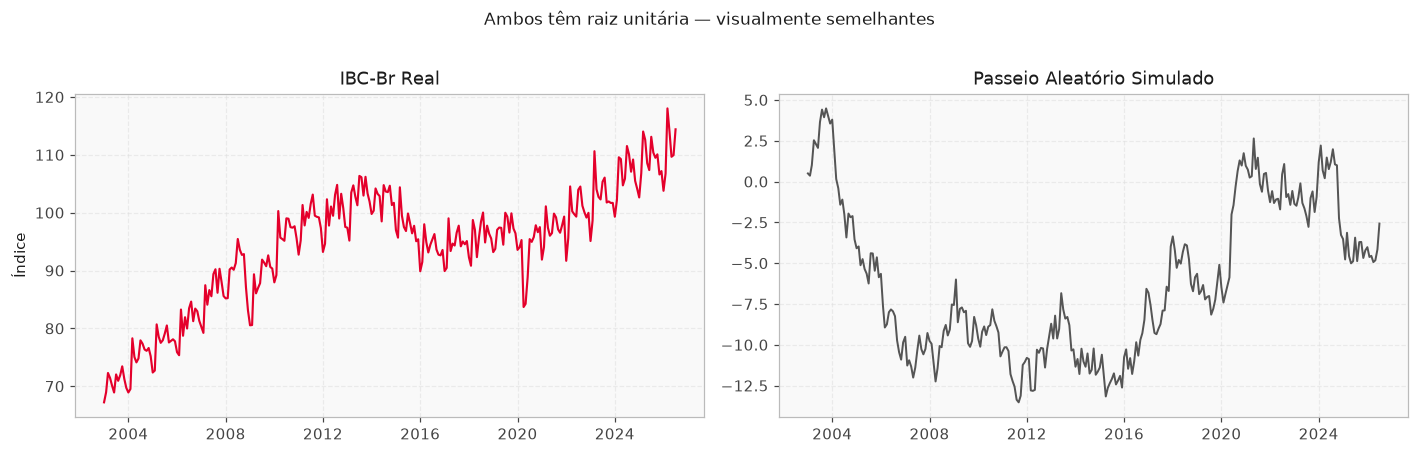

In [8]:
# Simulação de passeio aleatório
np.random.seed(42)
n_sim = len(ibc)
epsilon = np.random.normal(0, 1, n_sim)
rw = np.zeros(n_sim); rw[0] = epsilon[0]
for i in range(1, n_sim): rw[i] = rw[i-1] + epsilon[i]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ibc.index, ibc['ibc'], color=RED, lw=1.4)
axes[0].set_title('IBC-Br Real'); axes[0].set_ylabel('Índice'); axes[0].grid(True)
axes[1].plot(ibc.index, rw, color=GRAY, lw=1.3)
axes[1].set_title('Passeio Aleatório Simulado'); axes[1].grid(True)
plt.suptitle('Ambos têm raiz unitária — visualmente semelhantes', fontsize=11, y=1.02)
plt.tight_layout(); plt.show()


### 1.6 · Ruído Branco e Sazonalidade Residual

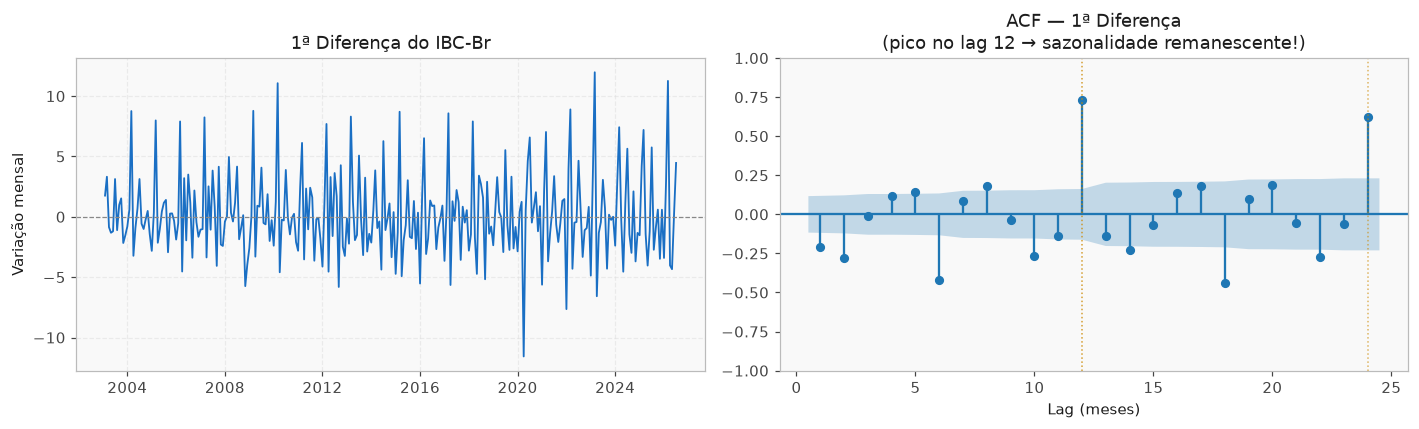

💡 Pico no lag 12 → sazonalidade anual não removida → precisamos de diff(12)!


In [9]:
# ACF da 1ª diferença
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ibc.index[1:], ibc['ibc_diff'].dropna(), color=BLUE, lw=1.2)
axes[0].axhline(0, color='#888', ls='--', lw=0.8)
axes[0].set_title('1ª Diferença do IBC-Br'); axes[0].set_ylabel('Variação mensal'); axes[0].grid(True)

plot_acf(ibc['ibc_diff'].dropna(), ax=axes[1], lags=24, zero=False,
         title='ACF — 1ª Diferença\n(pico no lag 12 → sazonalidade remanescente!)')
axes[1].set_xlabel('Lag (meses)')
axes[1].axvline(12, color=YELLOW, lw=1, ls=':', alpha=0.8)
axes[1].axvline(24, color=YELLOW, lw=1, ls=':', alpha=0.6)

plt.tight_layout(); plt.show()
print("💡 Pico no lag 12 → sazonalidade anual não removida → precisamos de diff(12)!")


---
## 🔴 Parte 2 — Componentes e Decomposição

### 2.1 · Diferenciação Sazonal + Dummy Covid

$$\Delta\Delta_{12} y_t = \Delta y_t - \Delta y_{t-12}$$


Meses com dummy Covid: ['Jan/2020', 'Feb/2020', 'Mar/2020', 'Apr/2020', 'May/2020', 'Jun/2020']


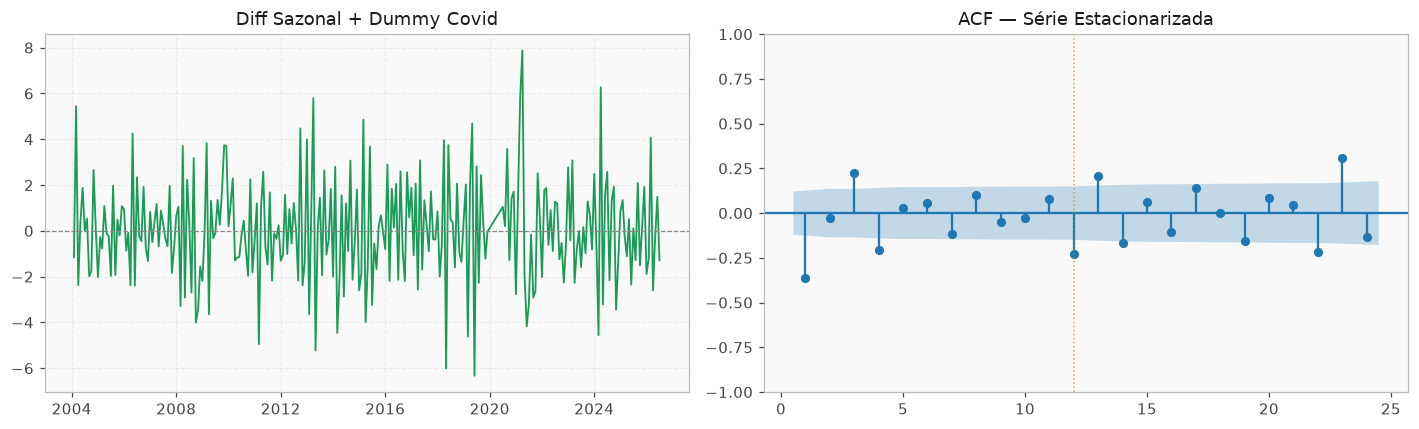

Lags fora do IC: 11/24 | max ACF=0.365 | IC=±0.121
💡 Lag 12 residual → sazonalidade não-estável → motiva o SARIMA!


In [10]:
# Diferença sazonal da 1ª diferença
ibc['ibc_diff_seas'] = ibc['ibc_diff'].diff(12)

# Dummy Covid: mar/2020 a ago/2020 como NaN
covid_idx = ibc.index[ibc.index >= '2020-01-01'][:6]
ibc.loc[covid_idx, 'ibc_diff_seas'] = np.nan
print(f"Meses com dummy Covid: {list(covid_idx.strftime('%b/%Y'))}")

serie_est = ibc['ibc_diff_seas'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(serie_est.index, serie_est.values, color=GREEN, lw=1.2)
axes[0].axhline(0, color='#888', ls='--', lw=0.8)
axes[0].set_title('Diff Sazonal + Dummy Covid'); axes[0].grid(True)
plot_acf(serie_est, ax=axes[1], lags=24, zero=False,
         title='ACF — Série Estacionarizada')
axes[1].axvline(12, color=YELLOW, lw=1, ls=':', alpha=0.7)
plt.tight_layout(); plt.show()

# Diagnóstico
from statsmodels.tsa.stattools import acf as acf_func
acf_vals = acf_func(serie_est, nlags=24)[1:]
ci = 1.96/np.sqrt(len(serie_est))
fora = np.sum(np.abs(acf_vals) > ci)
print(f"Lags fora do IC: {fora}/24 | max ACF={np.max(np.abs(acf_vals)):.3f} | IC=±{ci:.3f}")
print("💡 Lag 12 residual → sazonalidade não-estável → motiva o SARIMA!")


### 2.2 · Componentes de uma Série Temporal

| Componente | O que é | Exemplo | Característica |
|---|---|---|---|
| **Tendência** | Movimento de longo prazo | IBC-Br crescendo décadas | Persistente, suave |
| **Sazonalidade** | Padrão em período **fixo** | Queda em jan (13º), alta em dez | Período constante |
| **Ciclo** | Flutuações de período **variável** | Expansão/recessão (3–10 anos) | Menos previsível |
| **Resíduo** | Variação após remover demais | Choque Covid | Idealmente ruído branco |

**Modelo Aditivo:** $Y_t = T_t + S_t + C_t + R_t$  
**Multiplicativo:** se a amplitude sazonal cresce com o nível → $Y_t = T_t \times S_t \times R_t$ (ou log + aditivo)


### 2.3 · Decomposição Aditiva do IBC-Br

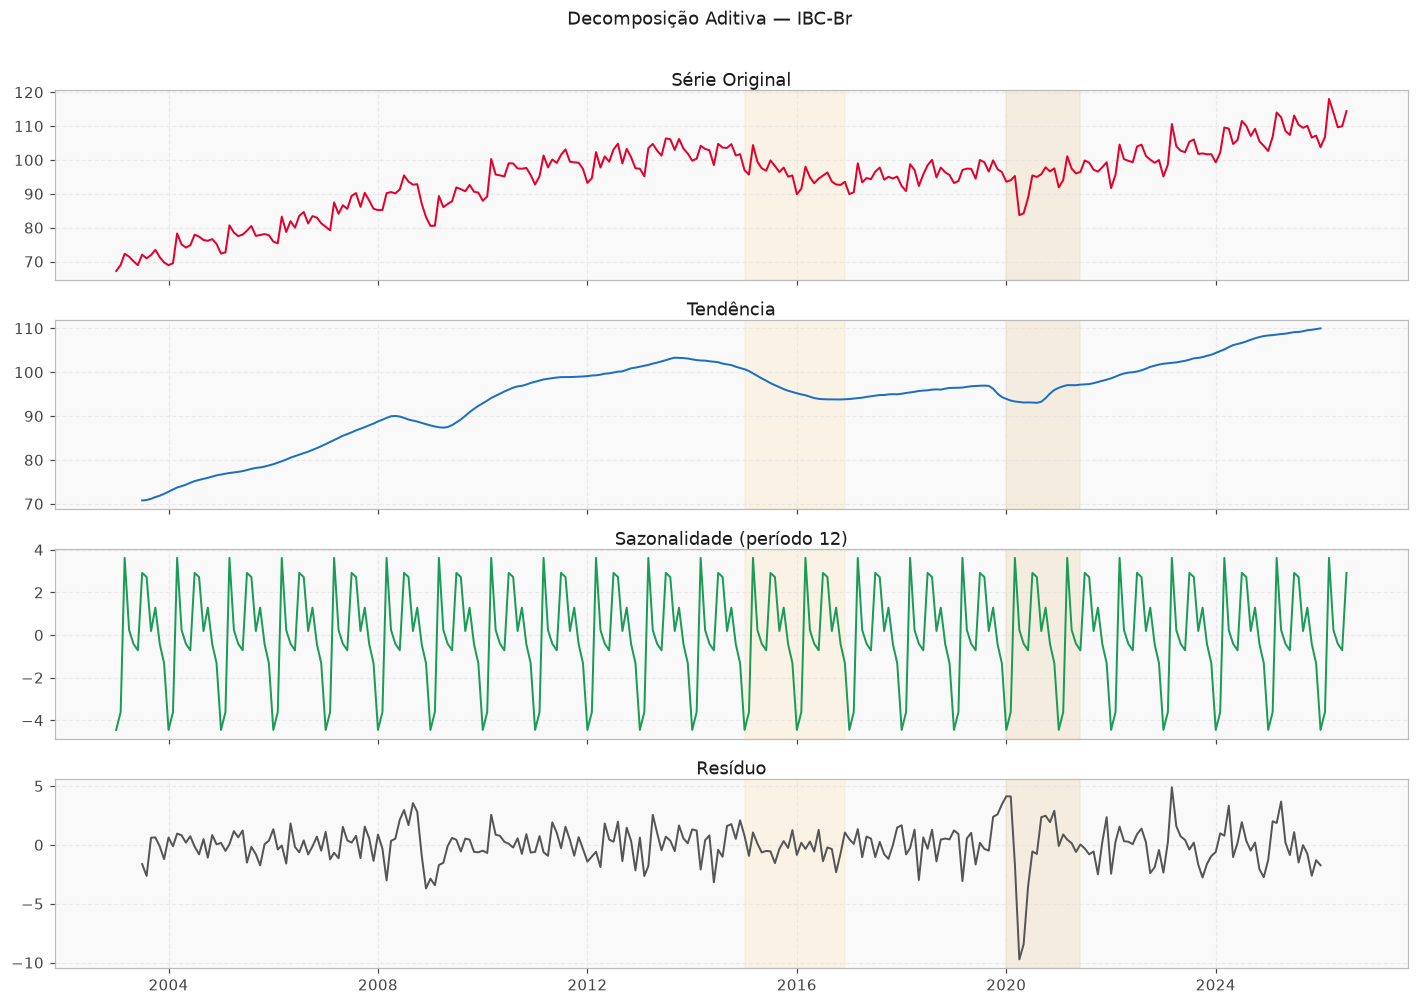

💡 Crise 2015-16 → tendência | Covid → resíduo


In [11]:
decomp = seasonal_decompose(ibc['ibc'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (comp, color, label) in zip(axes, [
    (decomp.observed,  RED,   'Série Original'),
    (decomp.trend,     BLUE,  'Tendência'),
    (decomp.seasonal,  GREEN, 'Sazonalidade (período 12)'),
    (decomp.resid,     GRAY,  'Resíduo'),
]):
    ax.plot(comp, color=color, lw=1.3)
    ax.set_title(label, pad=2); ax.grid(True)
    ax.axvspan(pd.Timestamp('2015-01-01'), pd.Timestamp('2016-12-01'),
               alpha=0.08, color='orange')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-06-01'),
               alpha=0.1, color=YELLOW)
fig.suptitle('Decomposição Aditiva — IBC-Br', fontsize=12, y=1.01)
plt.tight_layout(); plt.show()
print("💡 Crise 2015-16 → tendência | Covid → resíduo")


### 2.4 · Teste ADF — Nível vs Estacionarizado

In [12]:
def rodar_adf(serie, nome):
    """Teste ADF com resultado formatado."""
    serie = serie.dropna()
    k = int(np.floor((len(serie) - 1) ** (1/3)))
    res = adfuller(serie, maxlag=k, autolag=None, regression='c')
    conclusao = "✅ Rejeita H₀ → ESTACIONÁRIA" if res[1] < 0.05 else "⚠️  Não rejeita H₀ → RAIZ UNITÁRIA"
    print(f"{'='*50}")
    print(f"ADF — {nome}")
    print(f"{'='*50}")
    print(f"  Estatística ADF : {res[0]:.4f}")
    print(f"  p-value         : {res[1]:.4f}")
    print(f"  Lags usados     : {res[2]}")
    print(f"  Valores críticos:")
    for nivel, valor in res[4].items():
        print(f"    {nivel}: {valor:.4f}")
    print(f"  → {conclusao}\n")
    return res[1]

p1 = rodar_adf(ibc['ibc'],                'IBC-Br — Nível')
p2 = rodar_adf(ibc['ibc_diff_seas'],      'IBC-Br — Diff + Diff Sazonal + Dummy')


ADF — IBC-Br — Nível
  Estatística ADF : -1.7344
  p-value         : 0.4135
  Lags usados     : 6
  Valores críticos:
    1%: -3.4543
    5%: -2.8721
    10%: -2.5724
  → ⚠️  Não rejeita H₀ → RAIZ UNITÁRIA

ADF — IBC-Br — Diff + Diff Sazonal + Dummy
  Estatística ADF : -7.0868
  p-value         : 0.0000
  Lags usados     : 6
  Valores críticos:
    1%: -3.4561
    5%: -2.8729
    10%: -2.5728
  → ✅ Rejeita H₀ → ESTACIONÁRIA



---
## 🔴 Parte 3 — PACF e Modelos

### 3.1 · Processos AR(p) e MA(q)


In [13]:
from statsmodels.tsa.arima_process import ArmaProcess

np.random.seed(42)
n_sim = 500
eps = np.random.normal(0, 1, n_sim)

# AR(1) com phi=0.8
ar1 = np.zeros(n_sim); ar1[0] = eps[0]
for i in range(1, n_sim): ar1[i] = 0.8*ar1[i-1] + eps[i]

# MA(1) com theta=0.8
ma1 = np.array([eps[i] + 0.8*eps[i-1] for i in range(1, n_sim)])

# ARMA(1,1)
arma11 = np.zeros(n_sim); arma11[0] = eps[0]
for i in range(1, n_sim): arma11[i] = 0.6*arma11[i-1] + eps[i] + 0.5*eps[i-1]

print("Processos simulados:")
print(f"  AR(1)  phi=0.8  — ACF: decaimento exp | PACF: corte lag 1")
print(f"  MA(1)  theta=0.8 — ACF: corte lag 1 | PACF: decaimento exp")
print(f"  ARMA(1,1)        — ACF: decaimento | PACF: decaimento")


Processos simulados:
  AR(1)  phi=0.8  — ACF: decaimento exp | PACF: corte lag 1
  MA(1)  theta=0.8 — ACF: corte lag 1 | PACF: decaimento exp
  ARMA(1,1)        — ACF: decaimento | PACF: decaimento


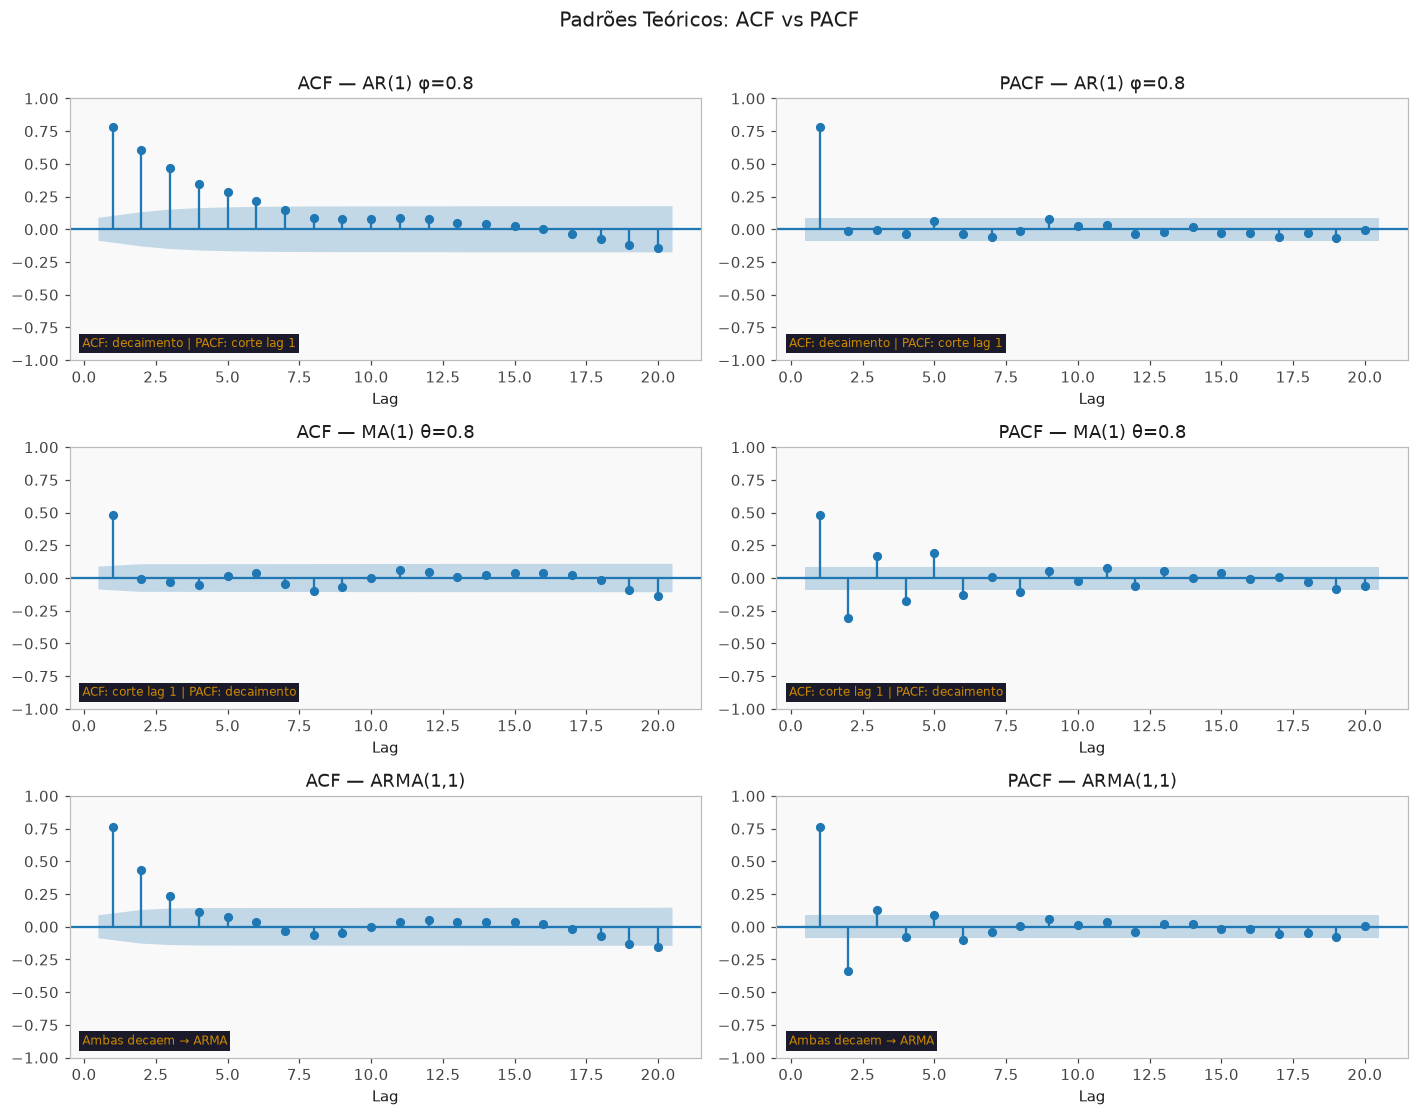

In [14]:
# Padrões teóricos: ACF vs PACF
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
dica = ['ACF: decaimento | PACF: corte lag 1',
        'ACF: corte lag 1 | PACF: decaimento',
        'Ambas decaem → ARMA']

for row, (serie, nome, hint) in enumerate([
    (ar1,    'AR(1) φ=0.8',   dica[0]),
    (ma1,    'MA(1) θ=0.8',   dica[1]),
    (arma11, 'ARMA(1,1)',      dica[2]),
]):
    plot_acf( pd.Series(serie), ax=axes[row,0], lags=20, zero=False,
              title=f'ACF — {nome}')
    plot_pacf(pd.Series(serie), ax=axes[row,1], lags=20, zero=False,
              title=f'PACF — {nome}')
    for ax in axes[row]:
        ax.set_xlabel('Lag')
        ax.text(0.02, 0.05, hint, transform=ax.transAxes, fontsize=8,
                color=YELLOW, bbox=dict(facecolor='#1a1a2a', edgecolor='none', pad=2))

fig.suptitle('Padrões Teóricos: ACF vs PACF', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()


### 3.2 · PACF — Definição e Algoritmo Levinson-Durbin

A PACF mede a correlação entre $Y_t$ e $Y_{t-k}$ **após remover o efeito dos lags intermediários**:

$$\phi_{kk} = \text{Cor}(Y_t - \hat{Y}_t,\ Y_{t-k} - \hat{Y}_{t-k})$$

**Tabela de identificação:**

| ACF | PACF | Modelo sugerido |
|---|---|---|
| Corte em $q$ | Decaimento | **MA($q$)** |
| Decaimento | Corte em $p$ | **AR($p$)** |
| Ambas decaem | Ambas decaem | **ARMA($p,q$)** |
| Decaimento lento | Pico lag 1 | Não estacionário → diferenciar |


### 3.3 · ACF e PACF do IBC-Br Estacionarizado

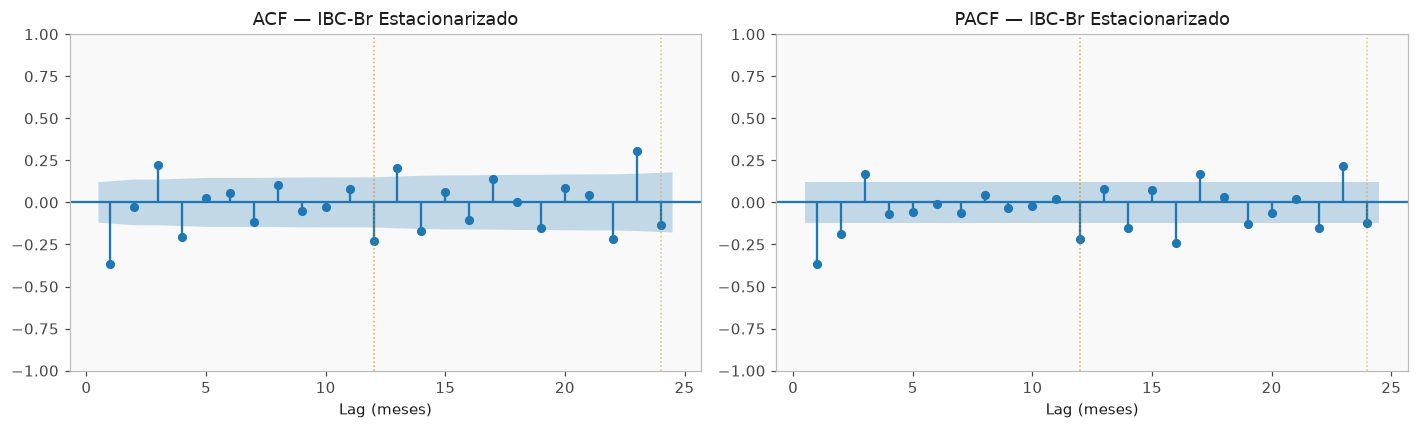

💡 Leitura:
   • ACF: corte após lag 1 → sugere MA(1) — q=1
   • Pico no lag 12 da ACF → sugere SMA(1) — Q=1
   • Candidato inicial: SARIMA(0,1,1)(0,1,1)₁₂


In [15]:
serie_est = ibc['ibc_diff_seas'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf( serie_est, ax=axes[0], lags=24, zero=False,
          title='ACF — IBC-Br Estacionarizado')
plot_pacf(serie_est, ax=axes[1], lags=24, zero=False,
          title='PACF — IBC-Br Estacionarizado')
for ax in axes:
    ax.set_xlabel('Lag (meses)')
    ax.axvline(12, color=YELLOW, lw=1, ls=':', alpha=0.7)
    ax.axvline(24, color=YELLOW, lw=1, ls=':', alpha=0.5)
plt.tight_layout(); plt.show()

print("💡 Leitura:")
print("   • ACF: corte após lag 1 → sugere MA(1) — q=1")
print("   • Pico no lag 12 da ACF → sugere SMA(1) — Q=1")
print("   • Candidato inicial: SARIMA(0,1,1)(0,1,1)₁₂")


### 3.4 · ARIMA e SARIMA

**ARIMA(p, d, q):** aplica $d$ diferenças antes do ARMA(p,q)

**SARIMA(p,d,q)(P,D,Q)$_s$:** dois andares — não-sazonal e sazonal

| Parâmetro | Significado | Como determinar |
|---|---|---|
| $p$, $q$ | Ordens AR/MA não-sazonais | PACF/ACF nos lags 1–11 |
| $d$ | Nº de diferenças regulares | Teste ADF |
| $P$, $Q$ | Ordens AR/MA sazonais | PACF/ACF nos lags 12, 24 |
| $D$ | Nº de diferenças sazonais | Inspeção da ACF sazonal |
| $s$ | Período sazonal | Dados (mensal → $s=12$) |

Para o IBC-Br: $d=1$, $D=1$, $s=12$ → candidato: **SARIMA(0,1,1)(0,1,1)₁₂**


---
## 🔴 Parte 4 — Modelagem na Prática

### 4.1 · AutoARIMA com StatsForecast


In [16]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

# Preparar dados no formato Nixtla
ibcbr_df = ibc[['ibc']].reset_index()
ibcbr_df.columns = ['ds', 'y']
ibcbr_df['unique_id'] = 'ibcbr'

sf = StatsForecast(
    models=[AutoARIMA(season_length=12)],
    freq='MS',
    n_jobs=1,
)
sf.fit(df=ibcbr_df)

# Inspecionar modelo selecionado
modelo = sf.fitted_[0, 0].model_
arma   = modelo['arma']  # [p, q, P, Q, s, d, D]
p, q, P, Q, s, d, D = arma
print(f"✅ Modelo selecionado: SARIMA({p},{d},{q})({P},{D},{Q})[{s}]")
print(f"   AIC  : {modelo['aic']:.3f}")
print(f"   BIC  : {modelo['bic']:.3f}")
print(f"   sigma: {modelo['sigma2']**0.5:.4f}")


✅ Modelo selecionado: SARIMA(3,1,3)(1,1,1)[12]
   AIC  : 1109.818
   BIC  : 1142.204
   sigma: 1.8080


### 4.2 · Previsão com Intervalos de Confiança

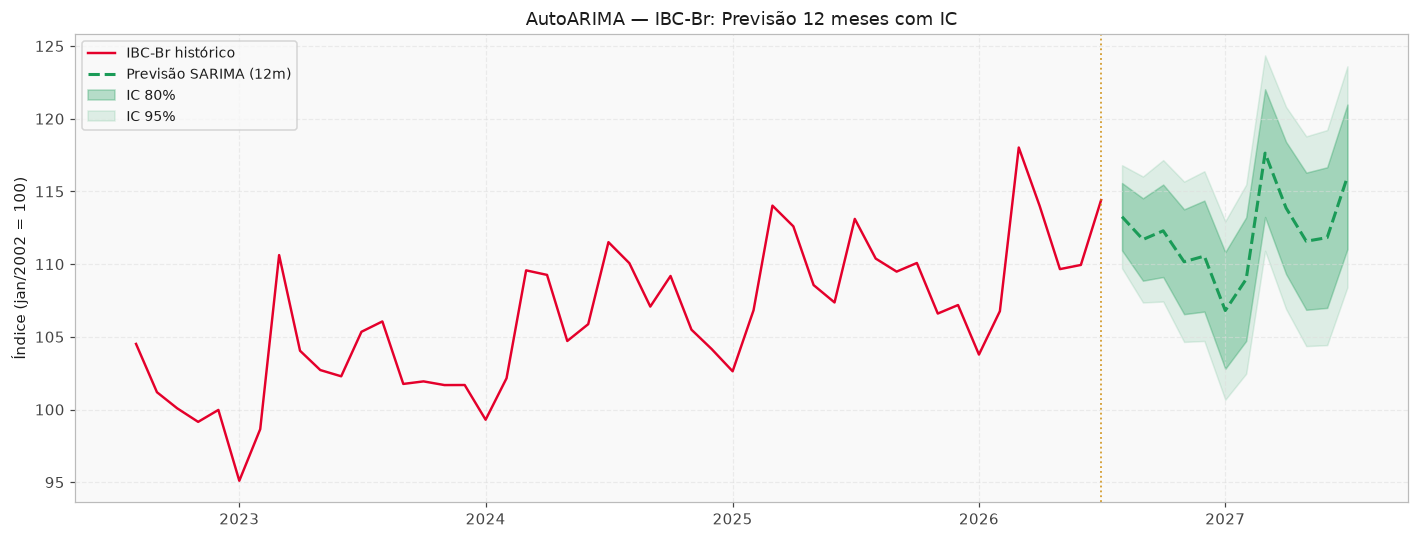

In [17]:
# Previsão 12 meses com IC 80% e 95%
previsao = sf.predict(h=12, level=[80, 95])

fig, ax = plt.subplots(figsize=(13, 5))
# Histórico (últimos 4 anos)
hist = ibc['ibc'].iloc[-48:]
ax.plot(hist.index, hist.values, color=RED, lw=1.6, label='IBC-Br histórico')
ax.plot(previsao['ds'], previsao['AutoARIMA'],
        color=GREEN, lw=2, ls='--', label='Previsão SARIMA (12m)')
ax.fill_between(previsao['ds'],
    previsao['AutoARIMA-lo-80'], previsao['AutoARIMA-hi-80'],
    color=GREEN, alpha=0.30, label='IC 80%')
ax.fill_between(previsao['ds'],
    previsao['AutoARIMA-lo-95'], previsao['AutoARIMA-hi-95'],
    color=GREEN, alpha=0.12, label='IC 95%')
ax.axvline(ibc.index[-1], color=YELLOW, lw=1.2, ls=':', alpha=0.8)
ax.set_title('AutoARIMA — IBC-Br: Previsão 12 meses com IC')
ax.set_ylabel('Índice (jan/2002 = 100)')
ax.legend(fontsize=9); ax.grid(True)
plt.tight_layout(); plt.show()


### 4.3 · Diagnóstico dos Resíduos

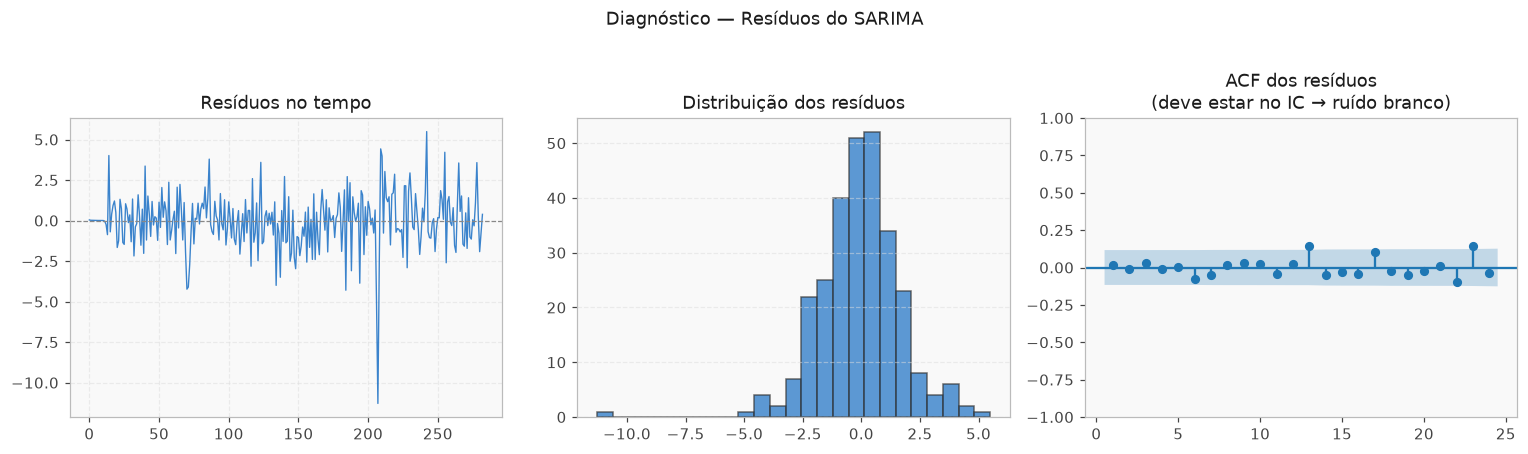

Teste Ljung-Box — p-value: 0.3596
✅ Resíduos são ruído branco!


In [18]:
# Diagnóstico: resíduos do modelo SARIMA
residuos = pd.Series(modelo.get('residuals', []))

if len(residuos) > 10:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].plot(residuos.values, color=BLUE, lw=0.9, alpha=0.85)
    axes[0].axhline(0, color='#888', ls='--', lw=0.8)
    axes[0].set_title('Resíduos no tempo'); axes[0].grid(True)
    axes[1].hist(residuos, bins=25, color=BLUE, alpha=0.7, edgecolor='#333')
    axes[1].set_title('Distribuição dos resíduos'); axes[1].grid(True, axis='y')
    plot_acf(residuos, ax=axes[2], lags=24, zero=False,
             title='ACF dos resíduos\n(deve estar no IC → ruído branco)')
    plt.suptitle('Diagnóstico — Resíduos do SARIMA', fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()

    lb = acorr_ljungbox(residuos, lags=[24], return_df=True)
    pval = lb['lb_pvalue'].values[0]
    print(f"Teste Ljung-Box — p-value: {pval:.4f}")
    print("✅ Resíduos são ruído branco!" if pval > 0.05 else "⚠️  Revisar modelo")
else:
    print("(Resíduos não disponíveis nesta versão do statsforecast)")


---
## 🏋️ Exercício Proposto

1. Carregue uma série diferente via API do BCB (sugestões abaixo)
2. Plote a série e a ACF — identifique tendência, sazonalidade e ruído
3. Aplique as diferenças necessárias para estacionarizar
4. Use a tabela ACF/PACF para propor um modelo SARIMA manualmente
5. Compare com o AutoARIMA — chegaram ao mesmo modelo?
6. Verifique se os resíduos são ruído branco (ACF + Ljung-Box)


In [19]:
# Escolha uma série e complete o exercício!
CODIGO = None  # ex: 24369 para desemprego, 433 para IPCA, 1 para câmbio

if CODIGO:
    minha_serie = bcb_serie(CODIGO, start='2003-01-01')
    col = minha_serie.columns[0]
    minha_serie.index = pd.to_datetime(minha_serie.index)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(minha_serie.index, minha_serie[col], color=RED, lw=1.4)
    axes[0].set_title(f'Série BCB {CODIGO}'); axes[0].grid(True)
    plot_acf(minha_serie[col], ax=axes[1], lags=24, zero=False, title='ACF — Nível')
    plt.tight_layout(); plt.show()
else:
    print("⬆️  Defina CODIGO e execute novamente!")
    print()
    print("Sugestões:")
    print("  CODIGO = 24369  # Taxa de desemprego mensal")
    print("  CODIGO = 433    # IPCA mensal")
    print("  CODIGO = 1      # Câmbio USD/BRL diário")
    print("  CODIGO = 21859  # Produção industrial mensal")
    print("  CODIGO = 11     # Taxa Selic diária")


⬆️  Defina CODIGO e execute novamente!

Sugestões:
  CODIGO = 24369  # Taxa de desemprego mensal
  CODIGO = 433    # IPCA mensal
  CODIGO = 1      # Câmbio USD/BRL diário
  CODIGO = 21859  # Produção industrial mensal
  CODIGO = 11     # Taxa Selic diária


---
## 📖 Referências

- **Forecasting: Principles and Practice** (3ª ed.) — Hyndman & Athanasopoulos  
  🔗 [otexts.com/fpp3](https://otexts.com/fpp3/)
- **Material do curso** — PADS Insper 2026  
  🔗 [padsinsper.github.io/202632-fa](https://padsinsper.github.io/202632-fa/)
- **StatsForecast** — [nixtlaverse.nixtla.io/statsforecast](https://nixtlaverse.nixtla.io/statsforecast/)
